# EDA ของ Feature Pipeline

## 1.1 สร้าง Notebook และกำหนดขอบเขต

ตรวจความพร้อมของฟีเจอร์รายวันสำหรับ SPY, IEF และ GLD และ Rolling Correlation ย้อนหลัง 20 วัน ก่อนวิเคราะห์การกระจายและความสัมพันธ์ของฟีเจอร์ ใช้ผลลัพธ์จาก Pipeline ตาม [Feature Contract](../docs/contract/feature_contract.md)

## 1.2 โหลด Parquet ทั้งสองตาราง

ตรวจว่ามีไฟล์ผลลัพธ์และแสดงขนาดกับตัวอย่างข้อมูล หากไฟล์ยังไม่ถูกสร้าง ให้รัน `python -m src.features.run --config config/features.yaml` จากโฟลเดอร์หลักของโปรเจกต์

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "config" / "features.yaml").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Open this notebook from within the project directory.")

curated = project_root / "data" / "curated"
feature_path = curated / "asset_volatility_features.parquet"
correlation_path = curated / "asset_rolling_correlations.parquet"
missing_paths = [path.name for path in (feature_path, correlation_path) if not path.is_file()]
if missing_paths:
    raise FileNotFoundError(
        f"Missing Parquet files: {', '.join(missing_paths)}. "
        "Run python -m src.features.run --config config/features.yaml from the project root."
    )

features = pd.read_parquet(feature_path)
correlations = pd.read_parquet(correlation_path)
display(pd.DataFrame(
    [features.shape, correlations.shape],
    index=[feature_path.stem, correlation_path.stem],
    columns=["rows", "columns"],
))
display(features.head(3), correlations.head(3))

,rows,columns
asset_volatility_features,3948,18
asset_rolling_correlations,1316,8


,date,ticker,ret_1d_t,ret_lag_1d,ret_lag_2d,ret_trailing_5d,ret_trailing_20d,rv_5d,rv_20d,rv_60d,rsi_14d,bb_width_20d,is_model_ready,is_warmup_buffer,feature_set_version,run_id,source_batch_id,feature_as_of_utc
0,2021-06-30,GLD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,True,2.0.0,feat_20261113T193156_5dc44aec,yf_20261108_124004_bddf,2026-11-13T19:31:56Z
1,2021-06-30,IEF,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,True,2.0.0,feat_20261113T193156_5dc44aec,yf_20261108_124004_bddf,2026-11-13T19:31:56Z
2,2021-06-30,SPY,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,True,2.0.0,feat_20261113T193156_5dc44aec,yf_20261108_124004_bddf,2026-11-13T19:31:56Z


,date,corr_spy_ief_20d,corr_spy_gld_20d,corr_ief_gld_20d,is_corr_ready,run_id,source_batch_id,computed_at_utc
0,2021-06-30,NaN,NaN,NaN,False,feat_20261113T193156_5dc44aec,yf_20261108_124004_bddf,2026-11-13T19:31:56Z
1,2021-07-01,NaN,NaN,NaN,False,feat_20261113T193156_5dc44aec,yf_20261108_124004_bddf,2026-11-13T19:31:56Z
2,2021-07-02,NaN,NaN,NaN,False,feat_20261113T193156_5dc44aec,yf_20261108_124004_bddf,2026-11-13T19:31:56Z


## 1.3 ตรวจคอลัมน์ คีย์ และช่วงเวลา

ตรวจว่ามีคอลัมน์ที่ใช้วิเคราะห์ครบ คีย์ไม่มีค่า NULL หรือซ้ำ และมีข้อมูลครบทั้งสาม ETF ตาราง Coverage รวมแถว warm-up เพื่อแสดงช่วงข้อมูลทั้งหมดที่อ่านได้

In [2]:
core_columns = [
    "ret_1d_t", "ret_lag_1d", "ret_lag_2d", "ret_trailing_5d",
    "ret_trailing_20d", "rv_5d", "rv_20d", "rv_60d",
]
experimental_columns = ["rsi_14d", "bb_width_20d"]
feature_columns = core_columns + experimental_columns
correlation_columns = ["corr_spy_ief_20d", "corr_spy_gld_20d", "corr_ief_gld_20d"]
expected_tickers = {"SPY", "IEF", "GLD"}

for name, frame, key, values, flags in [
    ("features", features, ["date", "ticker"], feature_columns,
     ["is_warmup_buffer", "is_model_ready"]),
    ("correlations", correlations, ["date"], correlation_columns, ["is_corr_ready"]),
]:
    missing_columns = set(key + values + flags) - set(frame.columns)
    if missing_columns:
        raise ValueError(f"{name}: missing columns {sorted(missing_columns)}")
    if frame.empty or frame[key + flags].isna().any().any() or frame.duplicated(key).any():
        raise ValueError(f"{name}: empty table, missing key or status, or duplicate key")
    frame["date"] = pd.to_datetime(frame["date"], errors="raise")

if set(features["ticker"]) != expected_tickers:
    raise ValueError(f"Unexpected ticker coverage: {sorted(features['ticker'].unique())}")

coverage = features.groupby("ticker")["date"].agg(rows="size", first_date="min", last_date="max")
coverage.loc["rolling correlations"] = [
    len(correlations), correlations["date"].min(), correlations["date"].max(),
]
display(coverage)

,rows,first_date,last_date
ticker,,,
GLD,1316,2021-06-30,2026-09-25
IEF,1316,2021-06-30,2026-09-25
SPY,1316,2021-06-30,2026-09-25
rolling correlations,1316,2021-06-30,2026-09-25


## 1.4 ตรวจค่า NULL และค่าที่ไม่เป็น finite

นับ NULL และค่าบวกหรือลบอนันต์แยกกันตามคอลัมน์และช่วงเวลา ค่า NULL ใน warm-up ช่วยบอกว่าสูตรต้องสะสมประวัตินานเท่าไร ส่วนค่าในช่วงวิเคราะห์ใช้ตรวจความพร้อมก่อนนำไปทำ EDA

In [3]:
in_analysis_period = ~features["is_warmup_buffer"]
analysis_dates = pd.Index(features.loc[in_analysis_period, "date"].unique())
correlation_in_period = correlations["date"].isin(analysis_dates)

def value_quality(frame, columns):
    values = frame[columns]
    return pd.DataFrame({
        "null": values.isna().sum(),
        "infinite": np.isinf(values).sum(),
    })

display(pd.concat({
    "warm-up": value_quality(features.loc[~in_analysis_period], feature_columns),
    "analysis period": value_quality(features.loc[in_analysis_period], feature_columns),
    "correlation in analysis period": value_quality(
        correlations.loc[correlation_in_period], correlation_columns
    ),
}, names=["period", "column"]))

null  infinite
period                         column                          
warm-up                        ret_1d_t             3         0
                               ret_lag_1d           6         0
                               ret_lag_2d           9         0
                               ret_trailing_5d     15         0
                               ret_trailing_20d    60         0
                               rv_5d               15         0
                               rv_20d              60         0
                               rv_60d             180         0
                               rsi_14d             42         0
                               bb_width_20d        57         0
analysis period                ret_1d_t             0         0
                               ret_lag_1d           0         0
                               ret_lag_2d           0         0
                               ret_trailing_5d      0         0
                               ret_trailing_20d     0         0
                               rv_5d                0         0
                               rv_20d               0         0
                               rv_60d               0         0
                               rsi_14d              0         0
                               bb_width_20d         0         0
correlation in analysis period corr_spy_ief_20d     0         0
                               corr_spy_gld_20d     0         0
                               corr_ief_gld_20d     0         0

## 1.5 แยก warm-up และสร้างชุดข้อมูลสำหรับ EDA

เก็บแถว warm-up ไว้ตรวจวันแรกที่แต่ละฟีเจอร์มีค่า finite แล้วสร้าง `eda_features` จากแถวที่พร้อมในช่วงวิเคราะห์ ส่วน `eda_correlations` ใช้วันในช่วงวิเคราะห์ที่ correlation พร้อม

In [4]:
warmup_features = features.loc[~in_analysis_period].copy()
eda_features = features.loc[in_analysis_period & features["is_model_ready"]].copy()
eda_correlations = correlations.loc[correlation_in_period & correlations["is_corr_ready"]].copy()

finite_features = features[feature_columns].where(np.isfinite(features[feature_columns]))
first_valid_dates = (
    finite_features.notna()
    .assign(ticker=features["ticker"], date=features["date"])
    .melt(id_vars=["ticker", "date"], var_name="feature", value_name="is_finite")
    .loc[lambda rows: rows["is_finite"]]
    .pivot_table(index="feature", columns="ticker", values="date", aggfunc="min")
    .reindex(feature_columns)
)
display(first_valid_dates)

ticker,GLD,IEF,SPY
feature,,,
ret_1d_t,2021-07-01,2021-07-01,2021-07-01
ret_lag_1d,2021-07-02,2021-07-02,2021-07-02
ret_lag_2d,2021-07-06,2021-07-06,2021-07-06
ret_trailing_5d,2021-07-08,2021-07-08,2021-07-08
ret_trailing_20d,2021-07-29,2021-07-29,2021-07-29
rv_5d,2021-07-08,2021-07-08,2021-07-08
rv_20d,2021-07-29,2021-07-29,2021-07-29
rv_60d,2021-09-24,2021-09-24,2021-09-24
rsi_14d,2021-07-21,2021-07-21,2021-07-21


## 1.6 สรุปความพร้อมก่อนเริ่มวิเคราะห์

เปรียบเทียบจำนวนแถวในช่วงวิเคราะห์กับจำนวนที่พร้อมใช้ และตรวจว่าตาราง correlation ครอบคลุมวันที่ต้องการ สำหรับข้อมูลรอบที่ตรวจครั้งแรก คาดว่าได้ 1,255 แถวต่อ ETF และ correlation พร้อม 1,255 วัน ตัวเลขในตารางด้านล่างคำนวณจากไฟล์ที่โหลดในแต่ละครั้ง

In [5]:
readiness = features.assign(
    warmup_rows=features["is_warmup_buffer"],
    rows_in_period=in_analysis_period,
    ready_rows=in_analysis_period & features["is_model_ready"],
).groupby("ticker")[["warmup_rows", "rows_in_period", "ready_rows"]].sum()
readiness["not_ready_rows"] = readiness["rows_in_period"] - readiness["ready_rows"]
display(readiness)

correlation_dates = pd.Index(correlations.loc[correlation_in_period, "date"])
display(pd.DataFrame([{
    "analysis_days": len(analysis_dates),
    "available_correlation_days": len(correlation_dates),
    "ready_correlation_days": len(eda_correlations),
    "not_ready_correlation_days": len(correlation_dates) - len(eda_correlations),
    "missing_correlation_days": len(analysis_dates.difference(correlation_dates)),
}], index=["rolling correlations"]))

,warmup_rows,rows_in_period,ready_rows,not_ready_rows
ticker,,,,
GLD,61,1255,1255,0
IEF,61,1255,1255,0
SPY,61,1255,1255,0


,analysis_days,available_correlation_days,ready_correlation_days,not_ready_correlation_days,missing_correlation_days
rolling correlations,1255,1255,1255,0,0


**ผลข้อ 1.6** ในช่วง 27 ก.ย. 2021 ถึง 25 ก.ย. 2026 มีฟีเจอร์พร้อมใช้ 1,255 แถวต่อ ETF หลังแยก warm-up 61 แถวต่อ ETF ฟีเจอร์ทั้ง 10 ตัวไม่มีค่า NULL หรืออนันต์ในช่วงวิเคราะห์ และ Rolling Correlation พร้อมครบ 1,255 วัน

## 2.1 สรุปสถิติรายฟีเจอร์แยกตาม ETF

ใช้ `eda_features` จากข้อ 1.5 สรุปค่ากลางและการกระจายตลอดช่วงวิเคราะห์ เปอร์เซ็นไทล์ P1 และ P99 แสดงปลายหาง ส่วน P25 และ P75 ครอบคลุมข้อมูลครึ่งกลาง ตารางใช้หน่วยเดิมจาก Parquet โดยผลตอบแทน, RV แบบ annualized และ `bb_width_20d` อยู่ในรูปทศนิยม ส่วน `rsi_14d` อยู่บนสเกล 0–100

In [6]:
feature_statistics = (
    eda_features.melt(
        id_vars="ticker", value_vars=feature_columns, var_name="feature", value_name="value"
    )
    .groupby(["ticker", "feature"])["value"]
    .describe(percentiles=[0.01, 0.25, 0.75, 0.99])
    .rename(columns={"1%": "p01", "25%": "p25", "50%": "median", "75%": "p75", "99%": "p99"})
    .reindex(pd.MultiIndex.from_product(
        [sorted(expected_tickers), feature_columns], names=["ticker", "feature"]
    ))
    [["count", "min", "p01", "p25", "median", "p75", "p99", "max"]]
)
feature_statistics["count"] = feature_statistics["count"].astype(int)
display(feature_statistics.round(4))

count      min      p01      p25   median      p75  \
ticker feature                                                                
GLD    ret_1d_t           1255  -0.1084  -0.0319  -0.0053   0.0008   0.0071   
       ret_lag_1d         1255  -0.1084  -0.0319  -0.0053   0.0008   0.0071   
       ret_lag_2d         1255  -0.1084  -0.0319  -0.0054   0.0008   0.0071   
       ret_trailing_5d    1255  -0.1225  -0.0649  -0.0108   0.0039   0.0185   
       ret_trailing_20d   1255  -0.1609  -0.1006  -0.0162   0.0118   0.0461   
       rv_5d              1255   0.0425   0.0503   0.1046   0.1439   0.1917   
       rv_20d             1255   0.0662   0.0700   0.1250   0.1470   0.1960   
       rv_60d             1255   0.0823   0.0868   0.1333   0.1530   0.1783   
       rsi_14d            1255  20.0425  26.1394  45.8600  53.5761  62.3498   
       bb_width_20d       1255   0.0177   0.0221   0.0434   0.0656   0.0892   
IEF    ret_1d_t           1255  -0.0179  -0.0119  -0.0032  -0.0001   0.0028   
       ret_lag_1d         1255  -0.0179  -0.0119  -0.0032  -0.0001   0.0028   
       ret_lag_2d         1255  -0.0179  -0.0119  -0.0032  -0.0001   0.0028   
       ret_trailing_5d    1255  -0.0396  -0.0235  -0.0068  -0.0004   0.0057   
       ret_trailing_20d   1255  -0.0657  -0.0497  -0.0153  -0.0003   0.0119   
       rv_5d              1255   0.0168   0.0235   0.0474   0.0637   0.0875   
       rv_20d             1255   0.0298   0.0324   0.0542   0.0674   0.0907   
       rv_60d             1255   0.0329   0.0364   0.0553   0.0702   0.0937   
       rsi_14d            1255  19.0230  26.7474  41.0546  49.3461  57.1903   
       bb_width_20d       1255   0.0059   0.0089   0.0197   0.0282   0.0384   
SPY    ret_1d_t           1255  -0.0603  -0.0297  -0.0046   0.0006   0.0063   
       ret_lag_1d         1255  -0.0603  -0.0297  -0.0046   0.0006   0.0063   
       ret_lag_2d         1255  -0.0603  -0.0297  -0.0046   0.0007   0.0063   
       ret_trailing_5d    1255  -0.1150  -0.0572  -0.0095   0.0040   0.0161   
       ret_trailing_20d   1255  -0.1204  -0.0964  -0.0157   0.0162   0.0391   
       rv_5d              1255   0.0317   0.0407   0.0920   0.1301   0.1810   
       rv_20d             1255   0.0614   0.0677   0.1079   0.1363   0.1822   
       rv_60d             1255   0.0877   0.0905   0.1144   0.1363   0.1817   
       rsi_14d            1255  21.5873  28.6530  46.4385  56.5896  64.3659   
       bb_width_20d       1255   0.0202   0.0238   0.0424   0.0580   0.0801   

                             p99      max  
ticker feature                             
GLD    ret_1d_t           0.0304   0.0616  
       ret_lag_1d         0.0304   0.0616  
       ret_lag_2d         0.0304   0.0616  
       ret_trailing_5d    0.0732   0.1149  
       ret_trailing_20d   0.1310   0.2432  
       rv_5d              0.4836   0.9703  
       rv_20d             0.5520   0.5826  
       rv_60d             0.4195   0.4255  
       rsi_14d           82.6985  88.2974  
       bb_width_20d       0.2303   0.2693  
IEF    ret_1d_t           0.0127   0.0223  
       ret_lag_1d         0.0127   0.0223  
       ret_lag_2d         0.0127   0.0223  
       ret_trailing_5d    0.0269   0.0422  
       ret_trailing_20d   0.0480   0.0601  
       rv_5d              0.1725   0.2308  
       rv_20d             0.1384   0.1435  
       rv_60d             0.1150   0.1199  
       rsi_14d           71.9491  80.5658  
       bb_width_20d       0.0703   0.0792  
SPY    ret_1d_t           0.0257   0.0999  
       ret_lag_1d         0.0257   0.0999  
       ret_lag_2d         0.0257   0.0999  
       ret_trailing_5d    0.0568   0.0828  
       ret_trailing_20d   0.1082   0.1576  
       rv_5d              0.4199   0.9097  
       rv_20d             0.5024   0.5243  
       rv_60d             0.3360   0.3394  
       rsi_14d           76.8636  81.9748  
       bb_width_20d       0.1708   0.1819

**ผลข้อ 2.1** IEF มีมัธยฐาน RV ต่ำที่สุดในทั้งสามระยะ มัธยฐาน `rv_20d` เท่ากับ 6.74% เทียบกับ SPY 13.63% และ GLD 14.70% แบบ annualized ส่วน GLD มีช่วง P1–P99 ของผลตอบแทนรายวันกว้างที่สุดที่ −3.19% ถึง +3.04%

## 2.2 ดูรูปทรงการกระจายของฟีเจอร์

ใช้ Histogram เพื่อดูรูปทรง และ Boxplot เพื่อเทียบค่ากลาง ช่วง P25–P75 และค่าปลายหาง แยกเป็นกลุ่มผลตอบแทน, RV และฟีเจอร์ทดลอง แต่ละฟีเจอร์ใช้ขอบ bin ชุดเดียวกันสำหรับ ETF ทั้งสาม แกนตั้งของ Histogram เป็นสัดส่วนข้อมูลต่อ bin ส่วนจุดนอกหนวดของ Boxplot อยู่ไกลเกิน 1.5 เท่าของ IQR จากขอบกล่อง

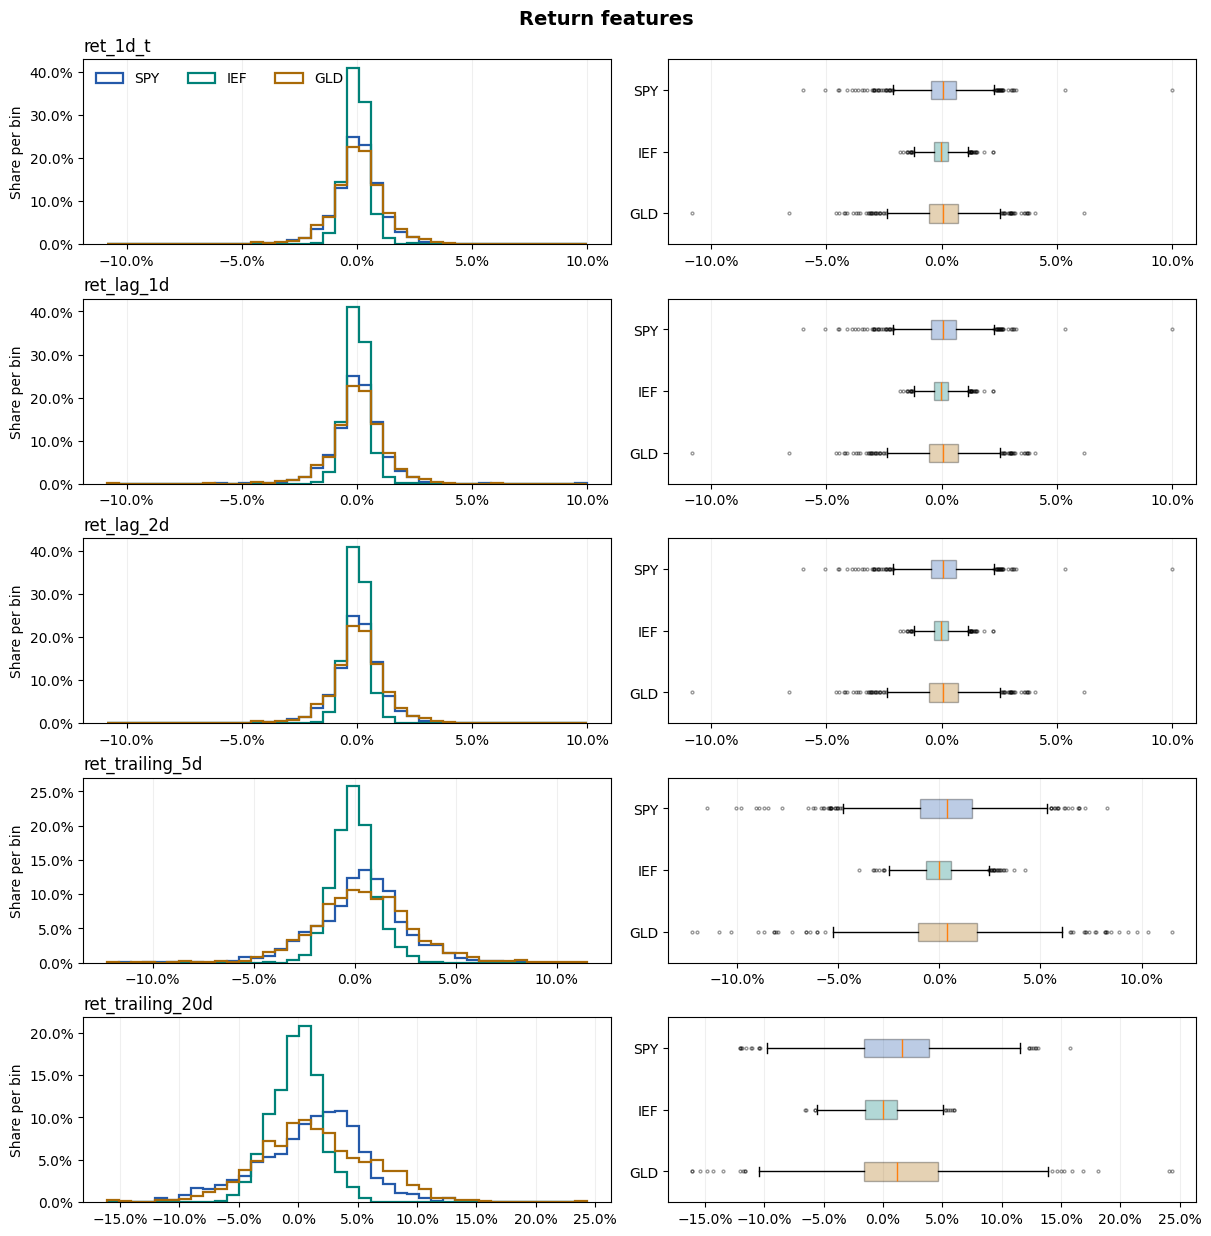

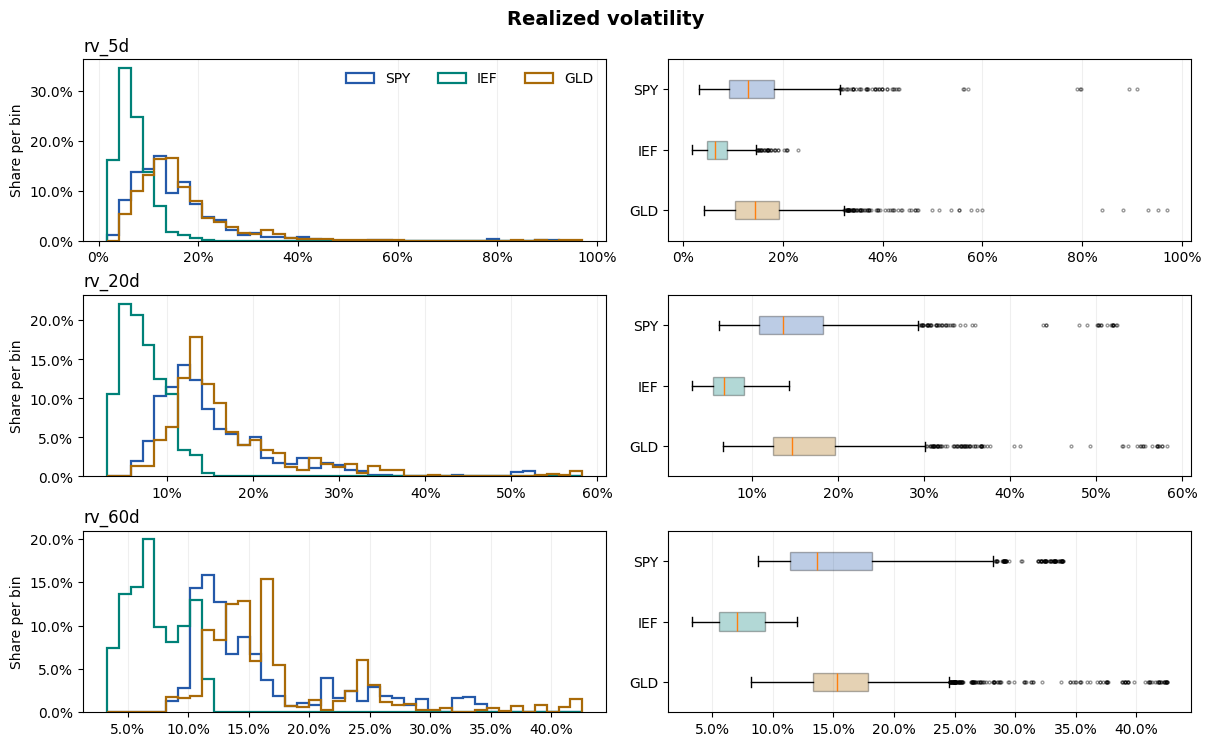

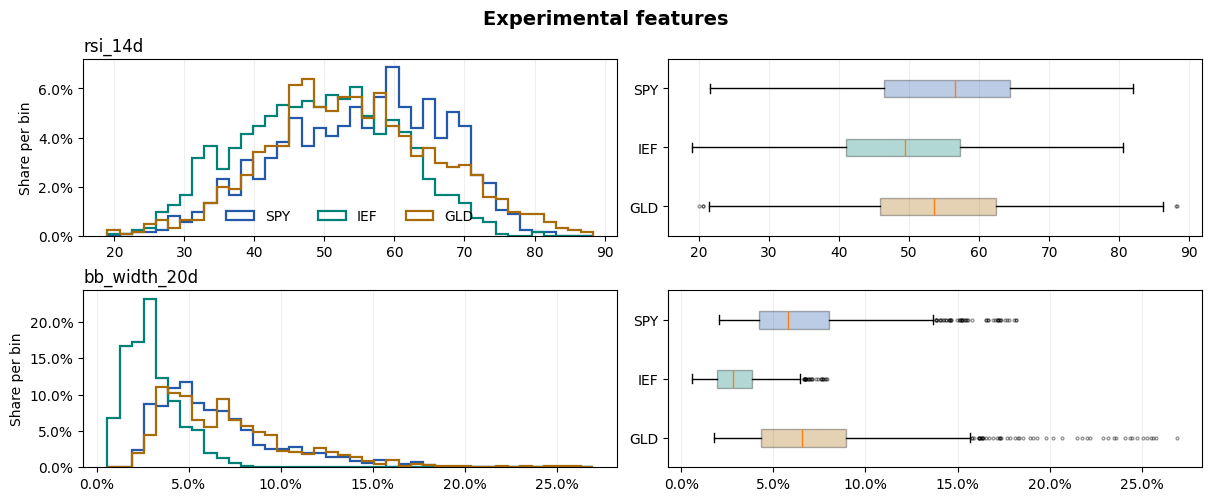

In [7]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ticker_order = ["SPY", "IEF", "GLD"]
ticker_colors = {"SPY": "#2459a9", "IEF": "#008178", "GLD": "#a96a08"}
feature_groups = {
    "Return features": core_columns[:5],
    "Realized volatility": core_columns[5:],
    "Experimental features": experimental_columns,
}

for group, columns in feature_groups.items():
    fig, axes = plt.subplots(
        len(columns), 2, figsize=(12, 2.45 * len(columns)), layout="constrained"
    )
    fig.suptitle(group, fontsize=14, fontweight="bold")

    for column, (hist_ax, box_ax) in zip(columns, axes):
        values = [
            eda_features.loc[eda_features["ticker"].eq(ticker), column].dropna().to_numpy()
            for ticker in ticker_order
        ]
        edges = np.histogram_bin_edges(np.concatenate(values), bins=40)
        for ticker, sample in zip(ticker_order, values):
            hist_ax.hist(
                sample, bins=edges, weights=np.full(sample.size, 1 / sample.size),
                histtype="step", linewidth=1.6, color=ticker_colors[ticker], label=ticker,
            )
        hist_ax.set_title(column, loc="left")
        hist_ax.yaxis.set_major_formatter(PercentFormatter(1))
        hist_ax.set_ylabel("Share per bin")

        boxes = box_ax.boxplot(
            values, vert=False, patch_artist=True,
            flierprops={"markersize": 2, "alpha": 0.4},
        )
        for ticker, box in zip(ticker_order, boxes["boxes"]):
            box.set_facecolor(ticker_colors[ticker])
            box.set_alpha(0.3)
        box_ax.set_yticks(range(1, len(ticker_order) + 1), ticker_order)
        box_ax.invert_yaxis()
        box_ax.set_xlim(hist_ax.get_xlim())
        for ax in (hist_ax, box_ax):
            ax.grid(axis="x", alpha=0.2)
            if column != "rsi_14d":
                ax.xaxis.set_major_formatter(PercentFormatter(1))

    axes[0, 0].legend(frameon=False, ncols=3)
    plt.show()
    plt.close(fig)

**ผลข้อ 2.2** ผลตอบแทนรายวันของ GLD มีหางซ้ายเด่น โดยต่ำสุด −10.84% ส่วน RV เบ้ขวาทั้งสามระยะและทุก ETF โดย `rv_5d` ของ GLD และ SPY มีปลายหางเด่นที่สุด ในกลุ่มทดลอง `rsi_14d` ค่อนข้างสมมาตร ขณะที่ `bb_width_20d` เบ้ขวาทั้งสาม ETF

## 2.3.1 ระบุวันอ้างอิงและตรวจ RV 5 วัน

เลือกวันผลตอบแทนรายวันต่ำสุดของ GLD และวันสูงสุดของ SPY จากชุด EDA หากมีค่าเท่ากันให้ใช้วันแรก เปรียบเทียบ RV 5 วันในวันอ้างอิงกับวันสูงสุดในกรอบ ±5 วันซื้อขาย และใช้ P99 ของ ETF นั้นเป็นเกณฑ์อ้างอิงว่าค่าสูงเพียงใดในชุดข้อมูลนี้

In [8]:
event_cases = {"GLD": "min", "SPY": "max"}
nearby_sessions = 5
event_windows = {}
event_rows = []

for ticker, extreme in event_cases.items():
    history = (
        eda_features.loc[eda_features["ticker"].eq(ticker)]
        .sort_values("date")
        .reset_index(drop=True)
    )
    returns = history["ret_1d_t"]
    event_index = returns.idxmin() if extreme == "min" else returns.idxmax()
    history["relative_session"] = history.index - event_index
    event_windows[ticker] = history
    event = history.loc[event_index]
    nearby = history.loc[history["relative_session"].between(-nearby_sessions, nearby_sessions)]
    local_peak = nearby.loc[nearby["rv_5d"].idxmax()]
    p99 = feature_statistics.loc[(ticker, "rv_5d"), "p99"]
    event_rows.append({
        "ticker": ticker,
        "event_date": event["date"],
        "daily_return": event["ret_1d_t"],
        "event_rv_5d": event["rv_5d"],
        "rv_5d_p99": p99,
        "event_at_or_above_p99": event["rv_5d"] >= p99,
        "nearby_peak_date": local_peak["date"],
        "peak_session": local_peak["relative_session"],
        "nearby_peak_rv_5d": local_peak["rv_5d"],
    })

event_summary = pd.DataFrame(event_rows).set_index("ticker")
display(event_summary.round(4))

,event_date,daily_return,event_rv_5d,rv_5d_p99,event_at_or_above_p99,nearby_peak_date,peak_session,nearby_peak_rv_5d
ticker,,,,,,,,
GLD,2026-01-30,-0.1084,0.8402,0.4836,True,2026-02-03,2,0.9703
SPY,2025-04-09,0.0999,0.9097,0.4199,True,2025-04-09,0,0.9097


**ผลข้อ 2.3.1** `rv_5d` สูงกว่า P99 ตั้งแต่วันอ้างอิงทั้งสองกรณี SPY สูงสุดในกรอบ ±5 วันซื้อขายในวันอ้างอิง 9 เม.ย. 2025 ที่ 90.97% ส่วน GLD สูงสุดที่ 97.03% ในวันที่ 3 ก.พ. 2026 หรือ 2 วันซื้อขายหลังวันอ้างอิง

## 2.3.2 เปรียบเทียบการตอบสนองของฟีเจอร์รอบเหตุการณ์

ใช้กรอบ 10 วันซื้อขายก่อนเหตุการณ์และ 30 วันซื้อขายหลังเหตุการณ์ โดยวัน 0 คือวันอ้างอิง ตารางเทียบค่าที่วัน −1 และวัน 0 กับจุดสูงสุดตั้งแต่วัน 0 เป็นต้นไป วัดระยะที่อยู่สูงด้วยจำนวนวันซื้อขายติดต่อกันที่ค่าไม่น้อยกว่า P90 ของฟีเจอร์และ ETF นั้น โดยเริ่มนับจากวันแรกที่ถึงเกณฑ์ตั้งแต่วัน 0 หากถึงขอบกรอบแล้วยังสูง ระยะที่เห็นเป็นค่าขั้นต่ำ เกณฑ์ P90 คำนวณจากทั้งช่วง EDA เพื่ออธิบายข้อมูลย้อนหลัง

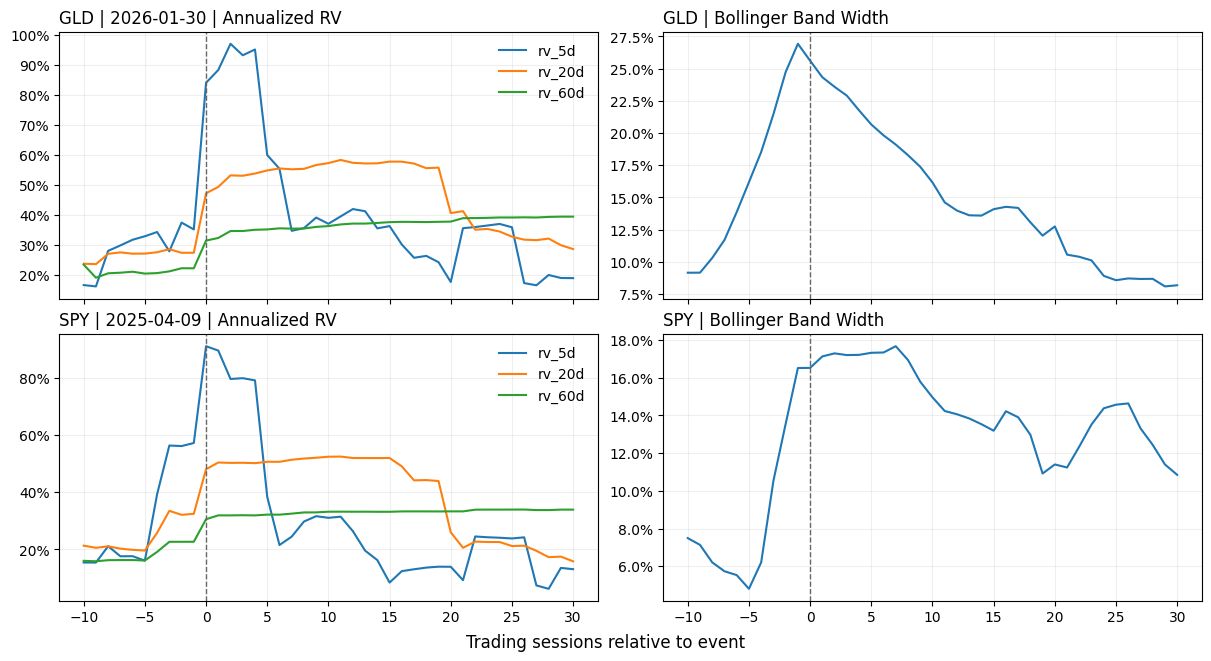

previous_value  event_value  peak_value  peak_session  \
ticker feature                                                               
GLD    rv_5d                 0.3506       0.8402      0.9703             2   
       rv_20d                0.2728       0.4711      0.5826            11   
       rv_60d                0.2208       0.3132      0.3933            30   
       bb_width_20d          0.2693       0.2561      0.2561             0   
SPY    rv_5d                 0.5717       0.9097      0.9097             0   
       rv_20d                0.3244       0.4802      0.5243            11   
       rv_60d                0.2269       0.3055      0.3394            26   
       bb_width_20d          0.1651       0.1652      0.1767             7   

                        p90  first_high_session  consecutive_high_sessions  \
ticker feature                                                               
GLD    rv_5d         0.2712                   0                         17   
       rv_20d        0.2746                   0                         31   
       rv_60d        0.2526                   0                         31   
       bb_width_20d  0.1249                   0                         19   
SPY    rv_5d         0.2432                   0                          6   
       rv_20d        0.2547                   0                         21   
       rv_60d        0.2613                   0                         31   
       bb_width_20d  0.1132                   0                         19   

                     high_at_end_of_streak_window  
ticker feature                                     
GLD    rv_5d                                False  
       rv_20d                                True  
       rv_60d                                True  
       bb_width_20d                         False  
SPY    rv_5d                                False  
       rv_20d                               False  
       rv_60d                                True  
       bb_width_20d                         False

In [9]:
sessions_before = 10
sessions_after = 30
response_columns = ["rv_5d", "rv_20d", "rv_60d", "bb_width_20d"]
response_rows = []
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True, layout="constrained")

for ticker, (rv_ax, width_ax) in zip(event_cases, axes):
    history = event_windows[ticker]
    window = history.loc[history["relative_session"].between(-sessions_before, sessions_after)]
    post_event = window.loc[window["relative_session"].ge(0)]
    event_date = event_summary.loc[ticker, "event_date"]
    rv_ax.set_title(f"{ticker} | {event_date:%Y-%m-%d} | Annualized RV", loc="left")
    width_ax.set_title(f"{ticker} | Bollinger Band Width", loc="left")

    for column in response_columns:
        ax = width_ax if column == "bb_width_20d" else rv_ax
        ax.plot(window["relative_session"], window[column], label=column)

        p90 = history[column].quantile(0.90)
        peak = post_event.loc[post_event[column].idxmax()]
        high = post_event[column].ge(p90).to_numpy()
        high_positions = np.flatnonzero(high)
        first_high_session = pd.NA
        high_streak = 0
        reaches_window_end = False
        if high_positions.size:
            start = high_positions[0]
            first_high_session = post_event["relative_session"].iloc[start]
            below_after_start = np.flatnonzero(~high[start:])
            reaches_window_end = not below_after_start.size
            high_streak = len(high) - start if reaches_window_end else below_after_start[0]

        response_rows.append({
            "ticker": ticker,
            "feature": column,
            "previous_value": window.loc[window["relative_session"].eq(-1), column].iloc[0],
            "event_value": post_event[column].iloc[0],
            "peak_value": peak[column],
            "peak_session": peak["relative_session"],
            "p90": p90,
            "first_high_session": first_high_session,
            "consecutive_high_sessions": high_streak,
            "high_at_end_of_streak_window": reaches_window_end,
        })

    rv_ax.legend(frameon=False)
    for ax in (rv_ax, width_ax):
        ax.axvline(0, color="0.4", linestyle="--", linewidth=1)
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.grid(alpha=0.2)

fig.supxlabel("Trading sessions relative to event")
plt.show()
plt.close(fig)

event_response = pd.DataFrame(response_rows).set_index(["ticker", "feature"])
display(event_response.round(4))

**ผลข้อ 2.3.2** ในสองกรณีที่เลือก `rv_20d` สูงสุดที่วัน +11 และอยู่ที่หรือเหนือ P90 นานกว่า `rv_5d` ส่วน `rv_60d` ยังอยู่เหนือเกณฑ์ที่ขอบกรอบวัน +30 ทั้งสองกรณี สำหรับ GLD ค่า `bb_width_20d` ลดลงในวันอ้างอิง ขณะที่ RV ทั้งสามระยะเพิ่มขึ้น ข้อสังเกตนี้อ้างอิงเหตุการณ์ที่เลือกสองวัน